https://chatgpt.com/c/6aeb2c2e-3300-83ec-9ac8-6d61466b7641

In [1]:

from pathlib import Path
from contextlib import ExitStack
import json

import earthaccess
import icechunk as ic
import xarray as xr

from obstore.store import LocalStore
from obspec_utils.registry import ObjectStoreRegistry
from virtualizarr import open_virtual_dataset
from virtualizarr.parsers import HDFParser


In [2]:


# --------------------------------------------------
# Configuration
# --------------------------------------------------

BBOX = (110.0, -25.0, 120.0, -15.0)
START_DATE = "2026-03-01"
END_DATE = "2026-05-31"

COLLECTION = "SWOT_L2_LR_SSH_EXPERT_D"

BASE = Path("/data/SWOT").resolve()
RAW = BASE / "raw"
REPO_PATH = BASE / "icechunk_virtual"

# Start with two files to validate the layout.
# Set to None after testing.
MAX_FILES = None



In [15]:

# --------------------------------------------------
# 1. Download complete SWOT granules
# --------------------------------------------------

def get_files():
    earthaccess.login()

    granules = earthaccess.search_data(
        short_name=COLLECTION,
        bounding_box=BBOX,
        temporal=(START_DATE, END_DATE),
    )
    print(f"Found {len(granules)} granules")
    
    if MAX_FILES is not None:
        granules = granules[:MAX_FILES]

    print(f"Downloading {len(granules)} granules")

    RAW.mkdir(parents=True, exist_ok=True)

    files = earthaccess.download(
        granules,
        local_path=str(RAW),
    )

    paths = sorted(
        Path(f).resolve()
        for f in files
        if str(f).endswith(".nc")
    )

    if not paths:
        raise RuntimeError("No NetCDF files downloaded")

    return paths, granules


paths, granules = get_files()


Found 99 granules


QUEUEING TASKS | :   0%|          | 0/99 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/99 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/99 [00:00<?, ?it/s]

In [16]:
granules[0]

Collection: {'Version': 'D', 'ShortName': 'SWOT_L2_LR_SSH_EXPERT_D'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -90, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 90}]}, 'Track': {'Cycle': 46, 'Passes': [{'Pass': 424}]}}}
Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2026-03-01T06:56:09.907Z', 'BeginningDateTime': '2026-03-01T06:04:12.141Z'}}
Size(MB): 32.103962898254395
Data: ['https://archive.swot.podaac.earthdata.nasa.gov/podaac-swot-ops-cumulus-protected/SWOT_L2_LR_SSH_D/SWOT_L2_LR_SSH_Expert_046_424_20260301T060426_20260301T065512_PID0_01.nc']

In [18]:
import h5py

# --------------------------------------------------
# 2. Open as local virtual datasets
# --------------------------------------------------
def get_string_variables(path):
    variables = []

    with h5py.File(path, "r") as f:
        def inspect(name, obj):
            if isinstance(obj, h5py.Dataset):
                if obj.dtype.kind in ("S", "U", "O"):
                    variables.append(name)

        f.visititems(inspect)

    return variables

def open_virtual_files(paths, stack):
    registry = ObjectStoreRegistry({
        "file:///": LocalStore()
    })

    datasets = []

    for path in paths:
        print("Virtualizing:", path.name)

        string_vars = get_string_variables(path)

        print("Excluding string variables:", string_vars)

        vds = stack.enter_context(
            open_virtual_dataset(
                url=path.as_uri(),
                registry=registry,
                parser=HDFParser(
                    drop_variables=string_vars
                ),
                loadable_variables=[],
            )
        )

        datasets.append(vds)

    return datasets

with ExitStack() as stack:
        datasets = open_virtual_files(paths, stack)

Virtualizing: SWOT_L2_LR_SSH_Expert_046_424_20260301T060426_20260301T065512_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Expert_046_437_20260301T171315_20260301T180443_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Expert_046_465_20260302T171346_20260302T180515_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Expert_046_562_20260306T042409_20260306T051537_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Expert_047_006_20260307T042440_20260307T051608_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Expert_047_034_20260308T042511_20260308T051639_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Expert_047_062_20260309T042542_20260309T051710_PID0_01.nc
Excluding string variables: ['polarization_karin']
Virtualizing: SWOT_L2_LR_SSH_Exper

In [30]:
import re

def get_cycle_pass(path, ds):
    # Prefer source NetCDF global attributes.
    cycle = ds.attrs.get("cycle_number")
    passage = ds.attrs.get("pass_number")

    if cycle is None or passage is None:
        # Fallback: SWOT filename convention
        match = re.search(
            r"Expert_(\d{3})_(\d{3})_",
            path.name,
        )
        if match is None:
            raise ValueError(
                f"Cannot determine cycle/pass: {path.name}"
            )
        cycle, passage = map(int, match.groups())

    return int(cycle), int(passage)


GEO_COORDS = [
    "latitude",
    "longitude",
    "latitude_nadir",
    "longitude_nadir",
]


def combine_swaths(paths, datasets):
    swaths = []
    seen = set()

    for path, ds in zip(paths, datasets):
        cycle, passage = get_cycle_pass(path, ds)
        key = (cycle, passage)

        if key in seen:
            print(f"Skipping duplicate {key}: {path.name}")
            continue

        seen.add(key)

        # Ensure geolocation variables are coordinates.
        coords = [v for v in GEO_COORDS if v in ds]

        missing = set(GEO_COORDS) - set(coords)
        if missing:
            raise ValueError(
                f"Missing geolocation variables in "
                f"{path.name}: {missing}"
            )

        ds = ds.set_coords(coords)

        # Add cycle and pass as new dimensions.
        ds = ds.expand_dims({
            "cycle_num": [cycle],
            "pass_num": [passage],
        })

        swaths.append(ds)

    combined = xr.combine_by_coords(
        swaths,
        compat="override",
        join="outer",
        data_vars="all",
        coords="all",
        combine_attrs="override",
    )

    # Explicitly preserve geolocation coordinates.
    combined = combined.set_coords(GEO_COORDS)

    return combined

combined = combine_swaths(paths, datasets)

print(combined.sizes)
print(combined["ssh_karin_2"].dims)

Skipping duplicate (49, 187): SWOT_L2_LR_SSH_Expert_049_187_20260424T090740_20260424T095813_PID0_02.nc
Skipping duplicate (49, 187): SWOT_L2_LR_SSH_Expert_049_187_20260424T090740_20260424T095813_PID0_03.nc


/opt/venvs/team-py/lib/python3.12/site-packages/xarray/core/duck_array_ops.py:276: RuntimeWarning: invalid value encountered in cast
  return converted.astype(dtype)


Frozen({'cycle_num': 6, 'pass_num': 23, 'num_lines': 9866, 'num_pixels': 69, 'num_sides': 2})
('cycle_num', 'pass_num', 'num_lines', 'num_pixels')


In [23]:
from collections import defaultdict

groups = defaultdict(list)

for path, ds in zip(paths, datasets):
    cycle, passage = get_cycle_pass(path, ds)
    groups[(cycle, passage)].append(path)

for key, files in groups.items():
    if len(files) > 1:
        print(f"\nDuplicate cycle/pass: {key}")
        for path in files:
            print(" ", path.name)


Duplicate cycle/pass: (49, 187)
  SWOT_L2_LR_SSH_Expert_049_187_20260424T090740_20260424T095813_PID0_01.nc
  SWOT_L2_LR_SSH_Expert_049_187_20260424T090740_20260424T095813_PID0_02.nc
  SWOT_L2_LR_SSH_Expert_049_187_20260424T090740_20260424T095813_PID0_03.nc


In [32]:
def write_icechunk(vds, paths):
    """
    Write a combined SWOT VirtualiZarr dataset to Icechunk.

    Expected dimensions:
        cycle_num
        pass_num
        num_lines
        num_pixels
        num_sides (where applicable)

    The original NetCDF files remain on disk.
    """

    import json
    import icechunk as ic

    # --------------------------------------------------
    # 1. Validate dimensions
    # --------------------------------------------------

    required_dims = {"cycle_num", "pass_num"}

    if not required_dims.issubset(vds.dims):
        raise ValueError(
            f"Missing dimensions: {required_dims - set(vds.dims)}"
        )

    print("Dataset dimensions:")
    print(dict(vds.sizes))

    print("Cycle numbers:", vds["cycle_num"].values)
    print("Pass numbers:", vds["pass_num"].values)

    # --------------------------------------------------
    # 2. Configure local virtual chunk references
    # --------------------------------------------------

    # All source NetCDF files must remain under RAW.
    raw_dir = RAW.resolve()

    file_prefix = raw_dir.as_uri().rstrip("/") + "/"

    for path in paths:
        path = path.resolve()

        if not path.is_relative_to(raw_dir):
            raise ValueError(
                f"Source file is outside RAW: {path}"
            )

    config = ic.RepositoryConfig.default()

    config.set_virtual_chunk_container(
        ic.VirtualChunkContainer(
            url_prefix=file_prefix,
            store=ic.local_filesystem_store(str(raw_dir)),
        )
    )

    # --------------------------------------------------
    # 3. Create Icechunk repository
    # --------------------------------------------------

    if REPO_PATH.exists():
        raise FileExistsError(
            f"Repository already exists: {REPO_PATH}"
        )

    storage = ic.local_filesystem_storage(
        str(REPO_PATH)
    )

    repo = ic.Repository.create(
        storage,
        config=config,
    )

    # --------------------------------------------------
    # 4. Write combined virtual dataset
    # --------------------------------------------------

    session = repo.writable_session("main")

    vds.vz.to_icechunk(session.store)

    snapshot = session.commit(
        "Create SWOT virtual dataset with "
        "cycle_num and pass_num dimensions"
    )

    repo.save_config()

    # --------------------------------------------------
    # 5. Save metadata index
    # --------------------------------------------------

    metadata = {
        "collection": COLLECTION,
        "bbox": list(BBOX),
        "start_date": START_DATE,
        "end_date": END_DATE,
        "dimensions": dict(vds.sizes),
        "cycle_numbers": [
            int(x) for x in vds["cycle_num"].values
        ],
        "pass_numbers": [
            int(x) for x in vds["pass_num"].values
        ],
        "source_files": [
            str(path.resolve()) for path in paths
        ],
        "snapshot": str(snapshot),
    }

    index_path = BASE / "virtual_index.json"

    index_path.write_text(
        json.dumps(metadata, indent=2)
    )

    print("\nIcechunk repository created")
    print("Path:", REPO_PATH)
    print("Snapshot:", snapshot)
    print("Dimensions:", metadata["dimensions"])

    return repo


import shutil
if REPO_PATH.exists():
    shutil.rmtree(REPO_PATH)

write_icechunk(combined, paths)


Dataset dimensions:
{'cycle_num': 6, 'pass_num': 23, 'num_lines': 9866, 'num_pixels': 69, 'num_sides': 2}
Cycle numbers: [46 47 48 49 50 51]
Pass numbers: [  6  34  62  75  78  90 103 118 131 159 187 284 312 340 353 368 381 396
 409 424 437 465 562]


  2026-11-09T05:49:26.719572Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343




Icechunk repository created
Path: /data/SWOT/icechunk_virtual
Snapshot: HGCQHQWGNBJ8QE4VFNMG
Dimensions: {'cycle_num': 6, 'pass_num': 23, 'num_lines': 9866, 'num_pixels': 69, 'num_sides': 2}


<icechunk.Repository (v2)>
storage:
    <icechunk.Storage>
    type: local filesystem
    path: /data/SWOT/icechunk_virtual
config: <RepositoryConfig ...>

In [10]:
import icechunk as ic
import xarray as xr

raw_dir = RAW.resolve()
file_prefix = raw_dir.as_uri().rstrip("/") + "/"

storage = ic.local_filesystem_storage(
    str(REPO_PATH)
)

repo = ic.Repository.open(
    storage,
    authorize_virtual_chunk_access={
        file_prefix: ic.credentials.LocalFileSystemAccess
    },
)

session = repo.readonly_session("main")

ds = xr.open_zarr(
    session.store,
    zarr_format=3,
    consolidated=False,
    chunks={},
    decode_cf=True,
    create_default_indexes=True,
)

print(ds.sizes)
print(ds["ssh_karin_2"].dims)

Frozen({'cycle_num': 6, 'pass_num': 23, 'num_lines': 9866, 'num_pixels': 69, 'num_sides': 2})
('cycle_num', 'pass_num', 'num_lines', 'num_pixels')


  2026-11-09T06:13:16.409217Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:343



In [11]:
cycle_ds = ds.sel(cycle_num=49)
swath = cycle_ds.isel(pass_num=2)

lat = swath["latitude"].values
lon = swath["longitude"].values

swath


<xarray.Dataset> Size: 400MB
Dimensions:                                (num_lines: 9866, num_pixels: 69,
                                            num_sides: 2)
Coordinates:
    cycle_num                              int64 8B 49
    latitude                               (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    longitude_nadir                        (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    longitude                              (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    latitude_nadir                         (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    pass_num                               int64 8B 62
Dimensions without coordinates: num_lines, num_pixels, num_sides
Data variables: (12/98)
    cross_track_angle                      (num_lines) float64 79kB dask.array<chunksize=(9866,), meta=np.ndarray>
    cross_track_distance                   (num_lines, num_pixels) float32 3MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    depth_or_elevation                     (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    doppler_centroid                       (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    geoid                                  (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    ancillary_surface_classification_flag  (num_lines, num_pixels) float32 3MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    ...                                     ...
    wind_speed_rad                         (num_lines, num_sides) float64 158kB dask.array<chunksize=(9866, 2), meta=np.ndarray>
    x_factor                               (num_lines, num_pixels) float32 3MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    wind_speed_karin                       (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    wind_speed_karin_2_qual                (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    wind_speed_model_u                     (num_lines, num_pixels) float64 5MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
    wind_speed_ssb_cor_source              (num_lines, num_pixels) float32 3MB dask.array<chunksize=(9866, 69), meta=np.ndarray>
Attributes: (12/62)
    Conventions:                                   CF-1.7
    title:                                         Level 2 Low Rate Sea Surfa...
    institution:                                   CNES
    source:                                        Ka-band radar interferometer
    history:                                       2026-03-08T22:18:52Z : Cre...
    platform:                                      SWOT
    ...                                            ...
    ellipsoid_semi_major_axis:                     6378137.0
    ellipsoid_flattening:                          0.0033528106647474805
    good_ocean_data_percent:                       69.96343675627753
    ssha_variance:                                 0.7898371423689805
    references:                                    V1.4.1
    equator_longitude:                             115.46

In [12]:
lat

array([[ 78.272006,  78.254093,  78.236179, ...,  77.089667,  77.071752,
         77.053837],
       [ 78.272051,  78.254138,  78.236224, ...,  77.089708,  77.071793,
         77.053878],
       [ 78.272068,  78.254155,  78.236241, ...,  77.089724,  77.071808,
         77.053893],
       ...,
       [-77.053767, -77.071682, -77.089597, ..., -78.236115, -78.254028,
        -78.271942],
       [-77.053747, -77.071662, -77.089577, ..., -78.236092, -78.254006,
        -78.27192 ],
       [-77.053701, -77.071617, -77.089532, ..., -78.236043, -78.253956,
        -78.27187 ]], shape=(9866, 69))

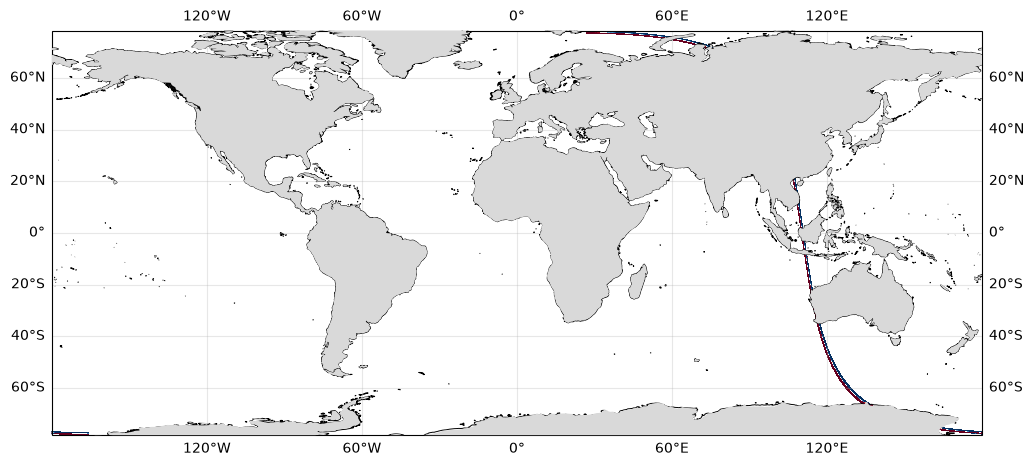

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

variable="ssha_karin_2"
bbox=(110, -35, 120, -25)
vmin=-0.3
vmax=0.3
cmap="RdBu_r"

fig, ax = plt.subplots(
        figsize=(12,8),
        subplot_kw={
            "projection": ccrs.PlateCarree()
        },
    )

ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=3)
ax.coastlines(resolution="50m", linewidth=0.7)
ax.gridlines(draw_labels=True, alpha=0.3)

data = swath[variable].values

data
mappable = ax.pcolormesh(
    lon,
    lat,
    data,
    shading="auto",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    transform=ccrs.PlateCarree(),
    rasterized=True,
)
plt.show()

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


def plot_swot_cycle(
    ds,
    cycle,
    variable="ssha_karin_2",
    bbox=None,
    cmap="RdBu_r",
    vmin=None,
    vmax=None,
    figsize=(12, 8),
):
    """
    Plot all available SWOT passes for one cycle.

    Parameters
    ----------
    ds : xr.Dataset
        Combined SWOT dataset with cycle_num and pass_num dimensions.
    cycle : int
        SWOT cycle number.
    variable : str or None
        Variable to plot. If None, plot swath footprints.
    bbox : tuple, optional
        Map extent (west, south, east, north).
    cmap : str
        Matplotlib colormap.
    vmin, vmax : float, optional
        Colour limits.
    figsize : tuple
        Figure size.

    Returns
    -------
    fig, ax
        Matplotlib figure and Cartopy axes.
    """

    if cycle not in ds.cycle_num.values:
        raise ValueError(f"Cycle {cycle} not found")

    cycle_ds = ds.sel(cycle_num=cycle)

    fig, ax = plt.subplots(
        figsize=figsize,
        subplot_kw={
            "projection": ccrs.PlateCarree()
        },
    )

    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=3)
    ax.coastlines(resolution="50m", linewidth=0.7)
    ax.gridlines(draw_labels=True, alpha=0.3)

    if bbox is not None:
        west, south, east, north = bbox
        ax.set_extent(
            [west, east, south, north],
            crs=ccrs.PlateCarree(),
        )

    mappable = None
    plotted_passes = []

    for passage in cycle_ds.pass_num.values:
        print(passage)
        swath = cycle_ds.sel(pass_num=passage)

        lat = swath["latitude"].values
        lon = swath["longitude"].values

        # Skip missing cycle/pass combinations introduced
        # by join="outer".
        if not np.isfinite(lat).any():
            continue

        if variable is None:
            # Plot swath footprint using sparse geolocation points.
            ax.scatter(
                lon[::20, ::3],
                lat[::20, ::3],
                s=1,
                color="tab:blue",
                transform=ccrs.PlateCarree(),
            )

        else:
            data = swath[variable].values
            correc = swath['height_cor_xover'].values
            data+=correc

            if not np.isfinite(data).any():
                continue

            mappable = ax.pcolormesh(
                lon,
                lat,
                data,
                shading="auto",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                transform=ccrs.PlateCarree(),
                rasterized=True,
            )

        plotted_passes.append(int(passage))

    if mappable is not None:
        fig.colorbar(
            mappable,
            ax=ax,
            shrink=0.8,
            label=variable,
        )

    ax.set_title(
        f"SWOT cycle {cycle} — "
        f"{len(plotted_passes)} passes"
    )

    print("Plotted passes:", plotted_passes)

    return fig, ax

def plot_swot_cycle(
    ds,
    cycle,
    variable="ssha_karin_2",
    bbox=None,
    direction="both",
    cmap="RdBu_r",
    vmin=None,
    vmax=None,
    figsize=(12, 8),
    stride=1,
):
    """
    Plot complete SWOT swaths for a selected cycle.

    Parameters
    ----------
    ds : xr.Dataset
        Combined SWOT Icechunk dataset.
        Geolocation and data must be CF-decoded.
    cycle : int
        SWOT cycle number.
    variable : str or None
        Variable to plot, or None for swath footprints.
    bbox : tuple or None
        Map extent (west, south, east, north).
        Does not clip the underlying swath data.
    direction : str
        "ascending", "descending", or "both".
    stride : int
        Subsampling factor for swath plotting.
    """

    if direction not in ("ascending", "descending", "both"):
        raise ValueError(
            "direction must be 'ascending', "
            "'descending', or 'both'"
        )

    if stride < 1:
        raise ValueError("stride must be >= 1")

    # Select cycle without requiring an Xarray index.
    cycles = ds["cycle_num"].values
    matches = np.flatnonzero(cycles == cycle)

    if len(matches) == 0:
        raise ValueError(f"Cycle {cycle} not found")

    cycle_ds = ds.isel(cycle_num=int(matches[0]))

    fig, ax = plt.subplots(
        figsize=figsize,
        subplot_kw={"projection": ccrs.PlateCarree()},
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="0.85",
        zorder=3,
    )
    ax.coastlines(resolution="50m", linewidth=0.7)
    ax.gridlines(draw_labels=True, alpha=0.3)

    if bbox is not None:
        west, south, east, north = bbox
        ax.set_extent(
            [west, east, south, north],
            crs=ccrs.PlateCarree(),
        )

    mappable = None
    plotted_passes = []

    for pass_idx, pass_num in enumerate(
        cycle_ds["pass_num"].values
    ):
        swath = cycle_ds.isel(pass_num=pass_idx)

        # ------------------------------------------
        # 1. Determine pass direction
        # ------------------------------------------
        nadir = swath["latitude_nadir"].values
        valid = np.isfinite(nadir)

        # Skip missing cycle/pass combinations.
        if valid.sum() < 2:
            continue

        nadir = nadir[valid]

        if nadir[-1] > nadir[0]:
            pass_direction = "ascending"
        else:
            pass_direction = "descending"

        if (
            direction != "both"
            and pass_direction != direction
        ):
            continue

        # ------------------------------------------
        # 2. Subsample full swath
        # ------------------------------------------
        swath = swath.isel(
            num_lines=slice(None, None, stride),
            num_pixels=slice(None, None, stride),
        )

        lat = swath["latitude"].values
        lon = swath["longitude"].values

        valid_geo = (
            np.isfinite(lat)
            & np.isfinite(lon)
        )

        if not valid_geo.any():
            continue

        # ------------------------------------------
        # 3. Plot complete swath
        # ------------------------------------------
        if variable is None:
            ax.scatter(
                lon[valid_geo],
                lat[valid_geo],
                s=0.5,
                color="tab:blue",
                transform=ccrs.PlateCarree(),
                rasterized=True,
            )
        else:
            data = swath[variable].values
            correc = swath['height_cor_xover'].values
            data+=correc

            data = np.ma.masked_where(
                ~valid_geo | ~np.isfinite(data),
                data,
            )

            if data.count() == 0:
                continue

            mappable = ax.pcolormesh(
                lon,
                lat,
                data,
                shading="auto",
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                transform=ccrs.PlateCarree(),
                rasterized=True,
            )

        plotted_passes.append(int(pass_num))

    if mappable is not None:
        fig.colorbar(
            mappable,
            ax=ax,
            shrink=0.8,
            label=variable,
        )

    ax.set_title(
        f"SWOT cycle {cycle} — "
        f"{direction} passes "
        f"({len(plotted_passes)} plotted)"
    )

    print("Plotted passes:", plotted_passes)

    return fig, ax


In [26]:
ds.cycle_num.values

array([46, 47, 48, 49, 50, 51])

Plotted passes: [6, 34, 62, 78, 90, 118, 284, 312, 340, 368, 396, 424, 562]


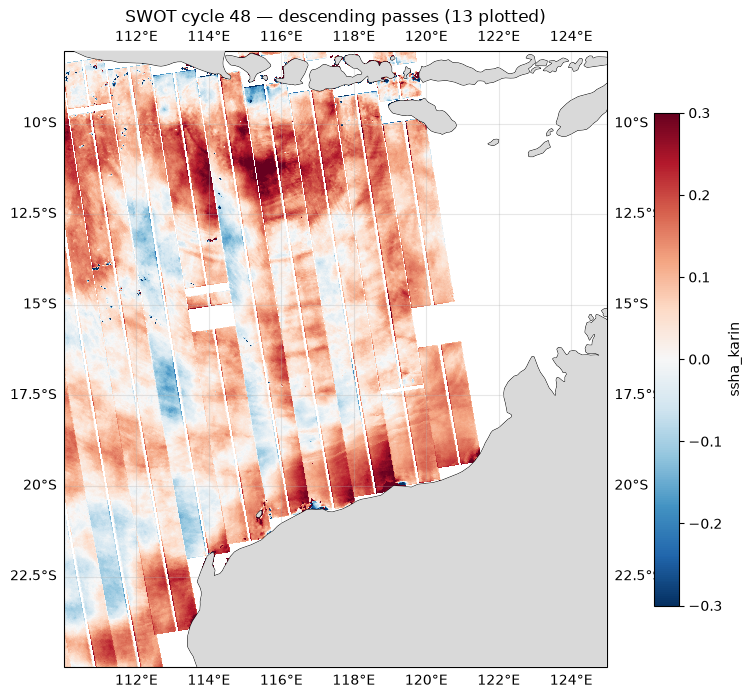

In [31]:
# ds = ds.set_xindex("cycle_num")
# ds = ds.set_xindex("pass_num")

fig, ax = plot_swot_cycle(
    ds,
    cycle=48,
    variable="ssha_karin",
    bbox=(110, -25, 125, -8),
    vmin=-0.3,
    vmax=0.3,
    #direction='ascending'
    direction='descending'

)

plt.show()